Nama: Johansen TAn
NIM: 2702241710

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [7]:
df = pd.read_csv('balanced_cleaned.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  2000 non-null   int64 
 1   content     2000 non-null   object
 2   score       2000 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 47.0+ KB


In [9]:
df.head()

,Unnamed: 0,content,score
0,0,so many ads,1
1,1,changed the UI and removed analysis features. ...,1
2,2,too much publicity,1
3,3,"I hate the advertisement. You guys sold out, a...",1
4,4,bad,1


# 3. Cleaning and Lemmatization

In [10]:
import re

# Non Words Cleaning
def cleaning(text):
  text = str(text)

  # Replace all except alphabets and space with spaces
  text = re.sub(r'[^a-zA-Z\s]', ' ', text)
  # Replace multiple spaces with one space and lower
  text = re.sub(r'\s+', ' ', text).strip().lower()

  return text

df['content'] = df['content'].apply(cleaning)

df.head(10)

,Unnamed: 0,content,score
0,0,so many ads,1
1,1,changed the ui and removed analysis features i...,1
2,2,too much publicity,1
3,3,i hate the advertisement you guys sold out and...,1
4,4,bad,1
5,5,lichess decides you have left the game when in...,1
6,6,why accuracy percentage is not shown in mobile...,1
7,7,play by their rules and they time you out for ...,1
8,8,if you cannot fairly properly measure minute g...,1
9,9,too many time stealing bots and hackers a play...,1


In [11]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet, stopwords

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [12]:
lemmatizer = WordNetLemmatizer()

# Part of Speech Tagging
def get_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Lemmatization
def lemmatization(text):
    tokens = nltk.word_tokenize(text)

    pos_tags = nltk.pos_tag(tokens)

    lemmatized_words = []
    for word, tag in pos_tags:
        wntag = get_pos(tag)

        lemma = lemmatizer.lemmatize(word, pos=wntag).lower()
        lemmatized_words.append(lemma)

    return " ".join(lemmatized_words)

df['content'] = df['content'].apply(lemmatization)

In [13]:
df.head(10)

,Unnamed: 0,content,score
0,0,so many ad,1
1,1,change the ui and remove analysis feature i wo...,1
2,2,too much publicity,1
3,3,i hate the advertisement you guy sell out and ...,1
4,4,bad,1
5,5,lichess decides you have leave the game when i...,1
6,6,why accuracy percentage be not show in mobile ...,1
7,7,play by their rule and they time you out for n...,1
8,8,if you can not fairly properly measure minute ...,1
9,9,too many time steal bot and hacker a player wh...,1


# 4. Text Representation with Word2Vec

In [14]:
from sklearn.model_selection import train_test_split

X = df['content']
y = df['score']

X_train_0, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val_0, X_test_0, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [15]:
# Tokenize
word_token_train = [nltk.word_tokenize(i) for i in X_train_0]
word_token_temp = [nltk.word_tokenize(i) for i in X_temp]
word_token_val = [nltk.word_tokenize(i) for i in X_val_0]
word_token_test = [nltk.word_tokenize(i) for i in X_test_0]

In [16]:
# Remove stopwords
stop_words = set(stopwords.words('english'))
exceptions = {
    'not', 'no', 'never', 'nor', 'none', 'neither',
    'but', 'however', 'very', 'too', 'so', 'always'
}

final_stopwords = stop_words - exceptions
# 70% data
filtered_tokens_train = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_train]
# 30% data
filtered_tokens_temp = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_temp]
# 15% data (half of temp)
filtered_tokens_val   = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_val]
# 15% data (half of temp)
filtered_tokens_test  = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_test]

In [17]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 61.2 MB/s eta 0:00:00


In [18]:
%pip install gensim
import gensim
from gensim.models import Word2Vec

# Skipgram
model_skipgram = gensim.models.Word2Vec(filtered_tokens_train, min_count = 3, vector_size = 75, window = 5, sg=1)

# Generate Vectors
def get_word_vector(model, word):
    try:
        return model.wv.get_vector(word)
    except KeyError:
        return None

def generate_word_vectors(filtered_tokens, word_vector_model, vector_length=75):
    X_vectors = []
    for tokens in filtered_tokens:
        vectorized_tokens = [get_word_vector(word_vector_model, word) for word in tokens]
        vectorized_tokens = [vector for vector in vectorized_tokens if vector is not None]

        if vectorized_tokens:
            average_vector = sum(vectorized_tokens) / len(vectorized_tokens)
            X_vectors.append(average_vector)
        else:
            X_vectors.append([0] * vector_length)
    return X_vectors

# 70% data
X_train_final = np.array(generate_word_vectors(filtered_tokens_train, model_skipgram))
# 30% data
X_temp_final = np.array(generate_word_vectors(filtered_tokens_temp, model_skipgram))
# 15% data (half of temp)
X_val_final   = np.array(generate_word_vectors(filtered_tokens_val, model_skipgram))
# 15% data (half of temp)
X_test_final  = np.array(generate_word_vectors(filtered_tokens_test, model_skipgram))

# 5. Model Training

## 5a. SVM

              precision    recall  f1-score   support

           1       0.33      0.42      0.37       120
           2       0.26      0.38      0.31       120
           3       0.43      0.08      0.14       120
           4       0.28      0.12      0.17       120
           5       0.41      0.68      0.51       120

    accuracy                           0.34       600
   macro avg       0.34      0.34      0.30       600
weighted avg       0.34      0.34      0.30       600



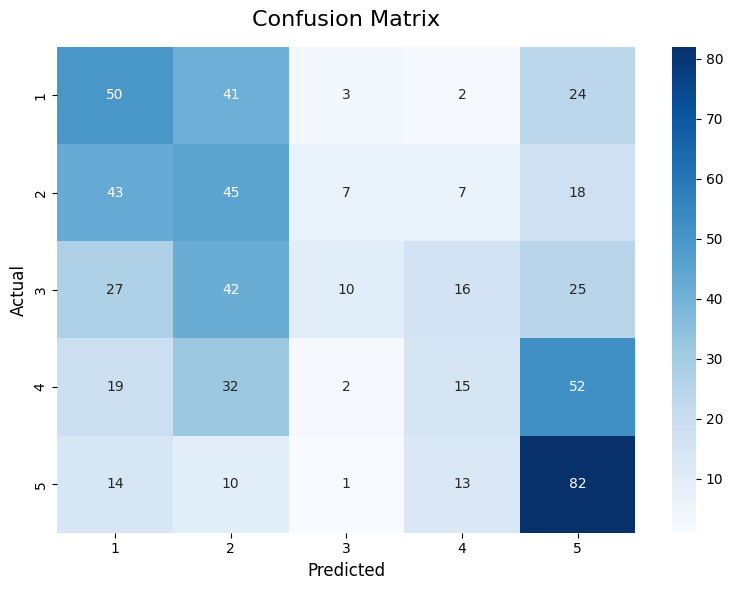

In [19]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Train Model
svm_model = LinearSVC(C=1.0, random_state=42, dual=True)
svm_model.fit(X_train_final, y_train)

# Test Model
y_pred = svm_model.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('svm', LinearSVC(random_state=42, dual=True))
])

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100],
    'svm__loss': ['hinge', 'squared_hinge'],

    'svm__intercept_scaling': [1, 2]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_final, y_train)
for param_name in sorted(param_grid.keys()):
    print(f"{param_name}: {grid_search.best_params_[param_name]}")

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

best_svm = grid_search.best_estimator_
final_accuracy = best_svm.score(X_temp_final, y_temp)
print(f"Final Test Accuracy with Best Model: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
svm__C: 10
svm__intercept_scaling: 1
svm__loss: squared_hinge

Best Cross-Validation Accuracy: 37.00%
Final Test Accuracy with Best Model: 35.33%


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


              precision    recall  f1-score   support

           1       0.33      0.42      0.37       120
           2       0.26      0.38      0.31       120
           3       0.43      0.08      0.14       120
           4       0.28      0.12      0.17       120
           5       0.41      0.68      0.51       120

    accuracy                           0.34       600
   macro avg       0.34      0.34      0.30       600
weighted avg       0.34      0.34      0.30       600



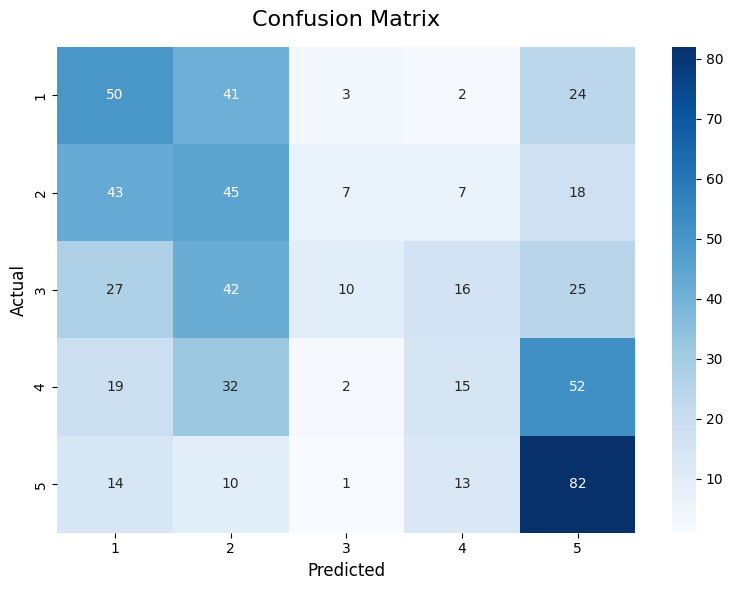

In [21]:
# Train Model
svm_model_2 = LinearSVC(C=1.0, random_state=42, dual=True)
svm_model_2.fit(X_train_final, y_train)

# Test Model
y_pred = svm_model_2.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

# 5B. Random Forest Classifier

              precision    recall  f1-score   support

           1       0.34      0.35      0.34       120
           2       0.30      0.34      0.32       120
           3       0.23      0.17      0.20       120
           4       0.27      0.22      0.24       120
           5       0.48      0.60      0.53       120

    accuracy                           0.34       600
   macro avg       0.32      0.34      0.33       600
weighted avg       0.32      0.34      0.33       600



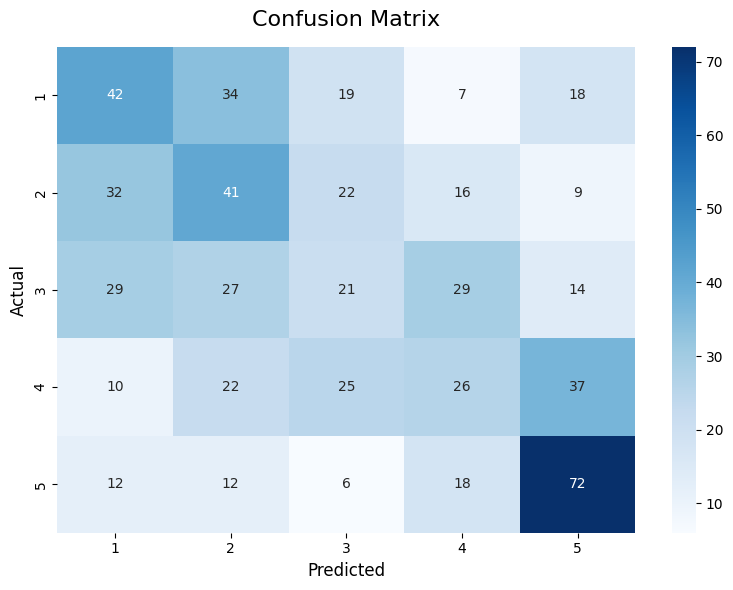

In [22]:
from sklearn.ensemble import RandomForestClassifier

# Train Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_final, y_train)

# Test Model
y_pred = rf_model.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

In [23]:
pipeline = Pipeline([
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid = {
    'rf__n_estimators': [50, 100],
    'rf__max_depth': [None, 50, 100],
    'rf__min_samples_split': [2, 5],
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_final, y_train)
for param_name in sorted(param_grid.keys()):
    print(f"{param_name}: {grid_search.best_params_[param_name]}")

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

best_svm = grid_search.best_estimator_
final_accuracy = best_svm.score(X_temp_final, y_temp)
print(f"Final Test Accuracy with Best Model: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
rf__max_depth: None
rf__min_samples_split: 2
rf__n_estimators: 100

Best Cross-Validation Accuracy: 34.43%
Final Test Accuracy with Best Model: 33.67%


              precision    recall  f1-score   support

           1       0.34      0.35      0.34       120
           2       0.30      0.34      0.32       120
           3       0.23      0.17      0.20       120
           4       0.27      0.22      0.24       120
           5       0.48      0.60      0.53       120

    accuracy                           0.34       600
   macro avg       0.32      0.34      0.33       600
weighted avg       0.32      0.34      0.33       600



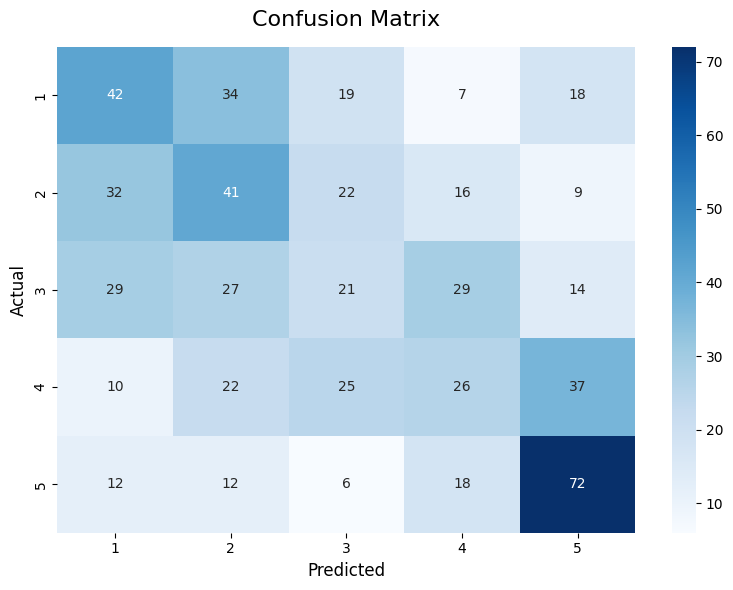

In [24]:
# Train Model
rf_model_2 = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model_2.fit(X_train_final, y_train)

# Test Model
y_pred = rf_model_2.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

## 5C. LSTM

### a. Building the model

In [25]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import classification_report, accuracy_score

embed_dim = 75
max_sen_len = 110

tok = Tokenizer()
tok.fit_on_texts(filtered_tokens_train)

vocab_size = 35000

seq_train = tok.texts_to_sequences(filtered_tokens_train)
seq_val   = tok.texts_to_sequences(filtered_tokens_val)
seq_test  = tok.texts_to_sequences(filtered_tokens_test)

pad_train = pad_sequences(seq_train, maxlen=max_sen_len, padding='post')
pad_val   = pad_sequences(seq_val, maxlen=max_sen_len, padding='post')
pad_test  = pad_sequences(seq_test, maxlen=max_sen_len, padding='post')



In [26]:
vocabulary_skipgram = model_skipgram.wv.index_to_key
word_vec_dict = {}
for word in vocabulary_skipgram:
    word_vec_dict[word] = model_skipgram.wv.get_vector(word)

embed_matrix = np.zeros(shape=(vocab_size, embed_dim))
for word, i in tok.word_index.items():
    embed_vector = word_vec_dict.get(word)
    if embed_vector is not None:
        embed_matrix[i] = embed_vector

In [27]:
from tensorflow.keras.optimizers import Adam
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embed_dim,
        weights=[embed_matrix],
        trainable=False,
        mask_zero=True
    ),

    LSTM(64, return_sequences=False),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

In [28]:
y_train_keras = np.array(y_train) - 1
y_val_keras   = np.array(y_val) - 1
y_test_keras  = np.array(y_test) - 1

history = model.fit(
    pad_train,
    y_train_keras,
    validation_data=(pad_val, y_val_keras),
    epochs=25,
    batch_size=32,
    verbose=1
)


Epoch 1/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 8s 103ms/step - accuracy: 0.2036 - loss: 1.6057 - val_accuracy: 0.2367 - val_loss: 1.6019
Epoch 2/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.2071 - loss: 1.6034 - val_accuracy: 0.2367 - val_loss: 1.5990
Epoch 3/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - accuracy: 0.2100 - loss: 1.6035 - val_accuracy: 0.2367 - val_loss: 1.5967
Epoch 4/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.2236 - loss: 1.5928 - val_accuracy: 0.2400 - val_loss: 1.5937
Epoch 5/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.2357 - loss: 1.5860 - val_accuracy: 0.2567 - val_loss: 1.5906
Epoch 6/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step - accuracy: 0.2286 - loss: 1.5862 - val_accuracy: 0.2567 - val_loss: 1.5879
Epoch 7/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.2379 - loss: 1.5861 - val_accuracy: 0.2467 - val_loss: 1.5852
Epoch 8/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.2679 - loss: 1.5789 - val_accuracy: 0.2600 - 

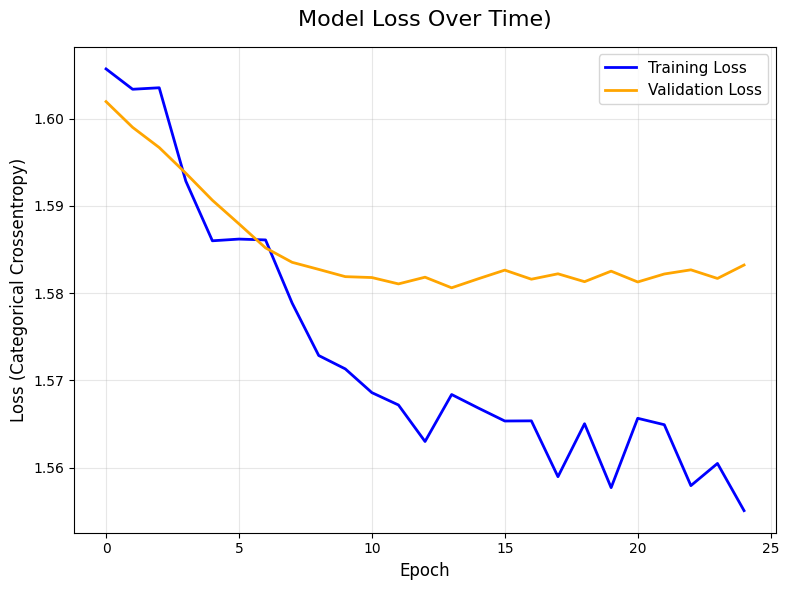

In [29]:
plt.figure(figsize=(8, 6))

plt.plot(history.history['loss'], label='Training Loss', color='blue', linewidth=2)

plt.plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)

plt.title('Model Loss Over Time)', fontsize=16, pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (Categorical Crossentropy)', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
y_pred_probs = model.predict(pad_test)
y_pred_keras = np.argmax(y_pred_probs, axis=1)

y_pred_final = y_pred_keras + 1
y_test_final = y_test_keras + 1


print(f"Overall Accuracy: {accuracy_score(y_test_final, y_pred_final) * 100:.2f}%\n")
print(classification_report(y_test_final, y_pred_final))

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step
Overall Accuracy: 27.33%

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        60
           2       0.27      0.47      0.34        60
           3       0.15      0.03      0.05        60
           4       0.25      0.15      0.19        60
           5       0.29      0.72      0.42        60

    accuracy                           0.27       300
   macro avg       0.19      0.27      0.20       300
weighted avg       0.19      0.27      0.20       300



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


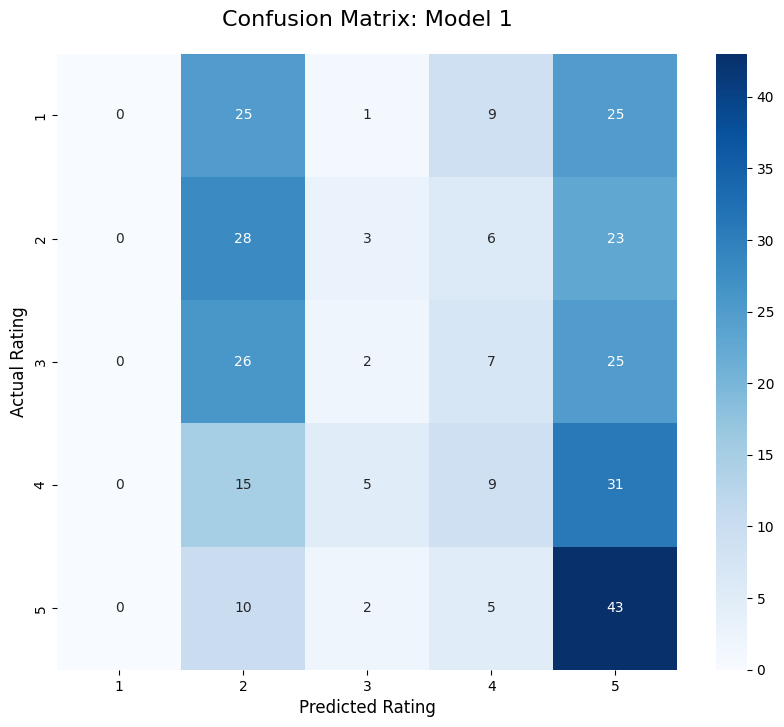

In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_final, y_pred_final)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])

plt.title('Confusion Matrix: Model 1', fontsize=16, pad=20)
plt.xlabel('Predicted Rating', fontsize=12)
plt.ylabel('Actual Rating', fontsize=12)
plt.show()

### b. Hyperparameter Tuning

In [32]:
model2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embed_dim,
        weights=[embed_matrix],
        trainable=False,
        mask_zero=True
    ),

    LSTM(32, return_sequences=False),
    Dense(16, activation='relu'),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

model2.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

In [33]:
history2 = model2.fit(
    pad_train,
    y_train_keras,
    validation_data=(pad_val, y_val_keras),
    epochs=25,
    batch_size=32,
    verbose=1
)

Epoch 1/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.1871 - loss: 1.6082 - val_accuracy: 0.2000 - val_loss: 1.6077
Epoch 2/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.2086 - loss: 1.6069 - val_accuracy: 0.2067 - val_loss: 1.6070
Epoch 3/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.2021 - loss: 1.6055 - val_accuracy: 0.2067 - val_loss: 1.6065
Epoch 4/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.2164 - loss: 1.6046 - val_accuracy: 0.2067 - val_loss: 1.6058
Epoch 5/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.2036 - loss: 1.6046 - val_accuracy: 0.2067 - val_loss: 1.6052
Epoch 6/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.2257 - loss: 1.6014 - val_accuracy: 0.2100 - val_loss: 1.6041
Epoch 7/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.2164 - loss: 1.6031 - val_accuracy: 0.2300 - val_loss: 1.6023
Epoch 8/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.2393 - loss: 1.6011 - val_accuracy: 0.2400 - v

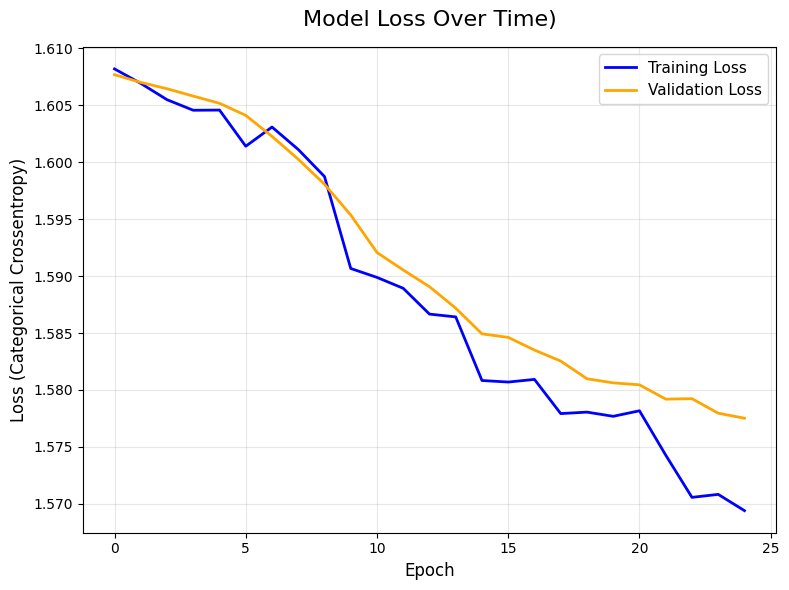

In [34]:
plt.figure(figsize=(8, 6))

plt.plot(history2.history['loss'], label='Training Loss', color='blue', linewidth=2)

plt.plot(history2.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)

plt.title('Model Loss Over Time)', fontsize=16, pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (Categorical Crossentropy)', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
y_pred_probs = model2.predict(pad_test)
y_pred_keras = np.argmax(y_pred_probs, axis=1)

y_pred_final = y_pred_keras + 1
y_test_final = y_test_keras + 1


print(f"Overall Accuracy: {accuracy_score(y_test_final, y_pred_final) * 100:.2f}%\n")
print(classification_report(y_test_final, y_pred_final))

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
Overall Accuracy: 27.00%

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        60
           2       0.25      0.52      0.34        60
           3       0.00      0.00      0.00        60
           4       0.24      0.12      0.16        60
           5       0.29      0.72      0.41        60

    accuracy                           0.27       300
   macro avg       0.16      0.27      0.18       300
weighted avg       0.16      0.27      0.18       300



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


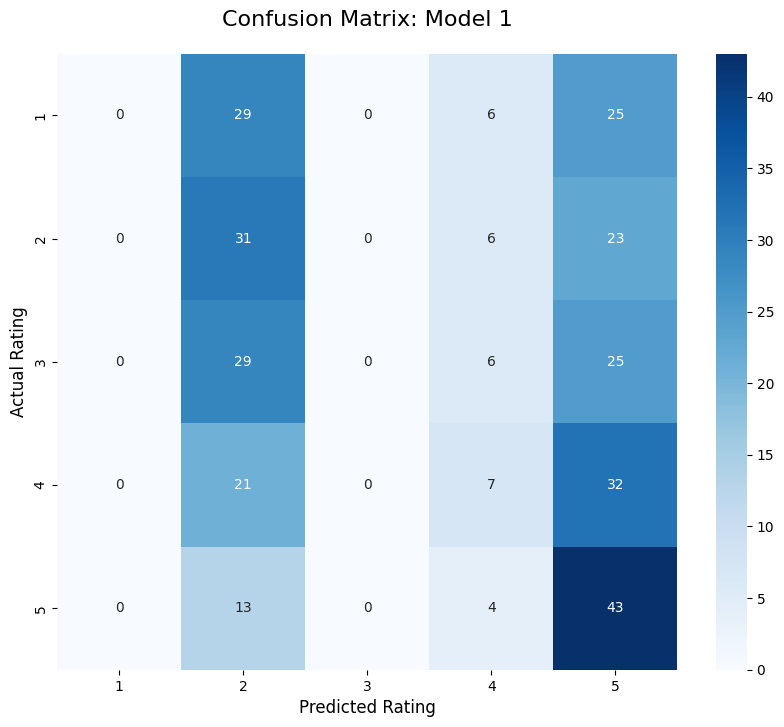

In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_final, y_pred_final)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])

plt.title('Confusion Matrix: Model 1', fontsize=16, pad=20)
plt.xlabel('Predicted Rating', fontsize=12)
plt.ylabel('Actual Rating', fontsize=12)
plt.show()